# k-NN vs Voting V6

For V6, I wanted to see if comparing distances between different classes would work better than using just the closest distance. I kept the same features as V5 and changed when the neural networks could replace k-NN's prediction.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

result_dir = project_root / 'results/model_comparison'
result_dir.mkdir(parents=True, exist_ok=True)

I loaded the same image split and checked the saved V4, V5 and NN predictions against the validation labels.

In [2]:
X, y, X_test, test_ids = load_task('image')
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
assert X_train.shape == (16000, 500) and X_val.shape == (4000, 500)
assert X.shape == (20000, 500) and X_test.shape == (5000, 500)
assert X.dtype == X_train.dtype == X_val.dtype == X_test.dtype == np.float32
v5_knn = pd.read_csv(result_dir / 'knn_vs_voting_v5_knn_validation.csv')
v5_vote = pd.read_csv(result_dir / 'knn_vs_voting_v5_image_validation.csv')
v4_vote = pd.read_csv(result_dir / 'knn_vs_voting_v4_image_validation.csv')
nn3 = pd.read_csv(project_root / 'results/image/nn_v3_validation.csv')
nn4 = pd.read_csv(project_root / 'results/image/nn_v4_validation.csv')
for frame in [v5_knn, v5_vote, v4_vote, nn3, nn4]:
    assert frame.columns.tolist() == ['validation_index', 'actual_label', 'predicted_label']
    assert len(frame) == 4000 and not frame.isna().any().any()
    assert frame.validation_index.is_unique
    assert np.array_equal(frame.validation_index, np.arange(4000))
    assert np.array_equal(frame.actual_label, y_val)
    for column in frame.columns:
        assert pd.api.types.is_integer_dtype(frame[column])
    assert frame.actual_label.between(0, 49).all() and frame.predicted_label.between(0, 49).all()

I kept the V5 transformation and found the nearest image from another class. I subtracted the nearest distance from that competing-class distance to get the gap.

In [3]:
def normalize_rows(features):
    lengths = np.linalg.norm(features, axis=1, keepdims=True)
    assert np.isfinite(features).all() and np.isfinite(lengths).all() and (lengths > 0).all()
    normalized = features / lengths
    assert normalized.shape == features.shape and normalized.dtype == np.float32
    assert np.allclose(np.linalg.norm(normalized, axis=1), 1, atol=1e-6)
    return normalized


def nearest_class_gaps(model, features):
    nearest_distances = []
    other_distances = []
    gaps = []
    nearest_labels = []
    for position, image in enumerate(features):
        distances = euclidean_distance(image, model.X_train)
        nearest_index = int(np.argmin(distances))
        knn_label = model.y_train[nearest_index]
        other_class = model.y_train != knn_label
        assert other_class.any()
        d1 = distances[nearest_index]
        d_other = np.min(distances[other_class])
        nearest_distances.append(d1)
        other_distances.append(d_other)
        gaps.append(d_other - d1)
        nearest_labels.append(knn_label)
        if (position + 1) % 1000 == 0:
            print('Calculated neighbors for', position + 1, 'images', flush=True)
    return (np.asarray(nearest_distances), np.asarray(other_distances),
            np.asarray(gaps), np.asarray(nearest_labels))

assert (X_train >= 0).all() and (X_val >= 0).all()
sqrt_train = np.sqrt(X_train)
feature_mean = sqrt_train.mean(axis=0)
assert feature_mean.shape == (500,) and feature_mean.dtype == np.float32
train_centered = normalize_rows(sqrt_train - 0.5 * feature_mean)
val_centered = normalize_rows(np.sqrt(X_val) - 0.5 * feature_mean)
model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
model.fit(train_centered, y_train)
start = perf_counter()
validation_distances, validation_other_distances, validation_gaps, knn_predictions = nearest_class_gaps(model, val_centered)
assert np.array_equal(knn_predictions, v5_knn.predicted_label.to_numpy())
assert np.array_equal(model.predict(val_centered[:5]), knn_predictions[:5])
for values in [validation_distances, validation_other_distances, validation_gaps]:
    assert values.shape == (4000,) and values.dtype == np.float32 and np.isfinite(values).all()
assert (validation_gaps >= -1e-6).all()
cutoff = np.percentile(validation_gaps[:2000], 30)
print('Validation gap cutoff:', cutoff)
print('All 4000 k-NN labels match V5.')
print(f'Validation neighbors calculated in {perf_counter() - start:.2f} s')

Calculated neighbors for 1000 images
Calculated neighbors for 2000 images
Calculated neighbors for 3000 images
Calculated neighbors for 4000 images
Validation gap cutoff: 0.01337018013000488
All 4000 k-NN labels match V5.
Validation neighbors calculated in 226.66 s


I used the NN label only when NN V3 and V4 agreed and the gap was at or below the 30th-percentile cutoff from the first 2000 images.

In [4]:
def conditional_vote(knn_labels, gaps, nn3_labels, nn4_labels, cutoff):
    assert len(knn_labels) == len(gaps) == len(nn3_labels) == len(nn4_labels)
    use_nn = (gaps <= cutoff) & (nn3_labels == nn4_labels)
    predictions = knn_labels.copy()
    predictions[use_nn] = nn3_labels[use_nn]
    return predictions, use_nn

v6_predictions, use_nn = conditional_vote(
    knn_predictions, validation_gaps, nn3.predicted_label.to_numpy(),
    nn4.predicted_label.to_numpy(), cutoff)
assert np.array_equal(v6_predictions[~use_nn], knn_predictions[~use_nn])
assert np.array_equal(v6_predictions[use_nn], nn3.predicted_label.to_numpy()[use_nn])
assert ((v6_predictions >= 0) & (v6_predictions <= 49)).all()
validation = pd.DataFrame({'validation_index': np.arange(4000),
    'actual_label': y_val, 'predicted_label': v6_predictions})
validation.to_csv(result_dir / 'knn_vs_voting_v6_image_validation.csv', index=False)
gap_details = pd.DataFrame({'validation_index': np.arange(4000),
    'actual_label': y_val, 'knn_label': knn_predictions,
    'nearest_distance': validation_distances, 'other_class_distance': validation_other_distances,
    'distance_gap': validation_gaps, 'nn3_label': nn3.predicted_label.to_numpy(),
    'nn4_label': nn4.predicted_label.to_numpy(), 'used_nn': use_nn,
    'predicted_label': v6_predictions})
gap_details.to_csv(result_dir / 'knn_vs_voting_v6_gap_validation.csv', index=False)
print('NN agreement and gap cutoff met:', int(use_nn.sum()))
print('Labels changed from k-NN:', int((v6_predictions != knn_predictions).sum()))

NN agreement and gap cutoff met: 476
Labels changed from k-NN: 393


I compared the new vote with V4 and V5, then checked both halves of the same validation set.

In [5]:
rows = []
for name, predictions in [
    ('V4 conditional', v4_vote.predicted_label.to_numpy()),
    ('V5 conditional', v5_vote.predicted_label.to_numpy()),
    ('V6 distance-gap conditional', v6_predictions)]:
    correct = int((predictions == y_val).sum())
    rows.append({'candidate': name, 'correct_count': correct,
                 'validation_samples': len(y_val), 'validation_accuracy': correct / len(y_val)})
summary = pd.DataFrame(rows)
summary.to_csv(result_dir / 'knn_vs_voting_v6_summary.csv', index=False)
print(summary.to_string(index=False))
v5_labels = v5_vote.predicted_label.to_numpy()
old_correct = v5_labels == y_val
new_correct = v6_predictions == y_val
print('Labels changed from V5:', int((v6_predictions != v5_labels).sum()))
print('Previously wrong predictions corrected:', int((~old_correct & new_correct).sum()))
print('Previously correct predictions lost:', int((old_correct & ~new_correct).sum()))
print('Net additional correct images:', int(new_correct.sum() - old_correct.sum()))
for start, end in [(0, 2000), (2000, 4000)]:
    old_count = int(old_correct[start:end].sum())
    new_count = int(new_correct[start:end].sum())
    print(f'Validation positions {start}..{end-1}: V5={old_count}/2000 ({old_count/2000:.3%}), '
          f'V6={new_count}/2000 ({new_count/2000:.3%}), gain={new_count-old_count}')

                  candidate  correct_count  validation_samples  validation_accuracy
             V4 conditional           2290                4000               0.5725
             V5 conditional           2306                4000               0.5765
V6 distance-gap conditional           2350                4000               0.5875
Labels changed from V5: 307
Previously wrong predictions corrected: 97
Previously correct predictions lost: 53
Net additional correct images: 44
Validation positions 0..1999: V5=1155/2000 (57.750%), V6=1178/2000 (58.900%), gain=23
Validation positions 2000..3999: V5=1151/2000 (57.550%), V6=1172/2000 (58.600%), gain=21


I plotted the three image accuracies to compare the voting rules.

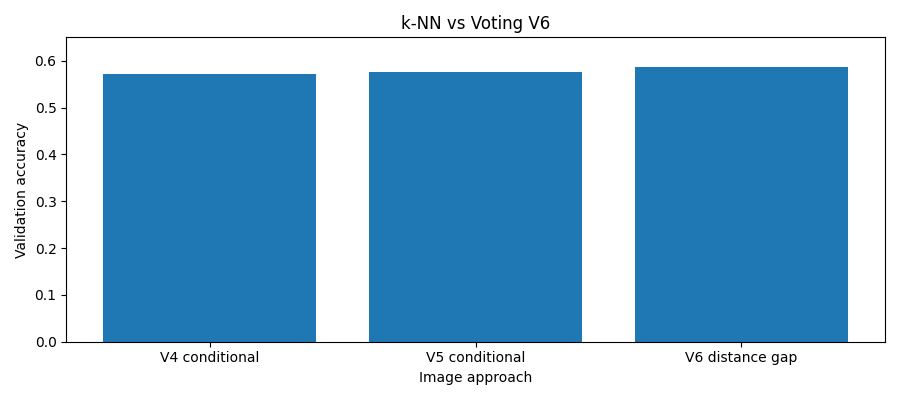

In [6]:
plt.figure(figsize=(9, 4))
plt.bar(['V4 conditional', 'V5 conditional', 'V6 distance gap'], summary.validation_accuracy)
plt.xlabel('Image approach')
plt.ylabel('Validation accuracy')
plt.title('k-NN vs Voting V6')
plt.ylim(0, 0.65)
plt.tight_layout()
plt.savefig(result_dir / 'knn_vs_voting_v6_accuracy.png')
plt.show()

I kept NN V3 for sentiment and calculated the equal average of the two task accuracies.

In [7]:
sentiment = pd.read_csv(project_root / 'results/sentiment/nn_v3_validation.csv')
raw_sentiment_labels = pd.read_csv(project_root / 'data/raw/sentiment_train.csv', usecols=['label']).label.to_numpy()
_, _, _, sentiment_y_val = split_train_val(
    np.arange(len(raw_sentiment_labels)).reshape(-1, 1), raw_sentiment_labels,
    val_fraction=0.2, seed=42)
assert len(sentiment) == 2400 and not sentiment.isna().any().any()
assert sentiment.validation_index.is_unique
assert np.array_equal(sentiment.validation_index, np.arange(2400))
assert np.array_equal(sentiment.actual_label, sentiment_y_val)
for column in ['validation_index', 'actual_label', 'predicted_label']:
    assert pd.api.types.is_integer_dtype(sentiment[column])
assert sentiment.predicted_label.between(0, 2).all()
sentiment_correct = int((sentiment.predicted_label == sentiment.actual_label).sum())
sentiment_accuracy = sentiment_correct / len(sentiment)
image_accuracy = float((v6_predictions == y_val).mean())
combined_accuracy = (image_accuracy + sentiment_accuracy) / 2
print(f'NN V3 sentiment: {sentiment_correct}/{len(sentiment)}, accuracy={sentiment_accuracy!r}')
print('Combined validation accuracy:', combined_accuracy)

NN V3 sentiment: 1639/2400, accuracy=0.6829166666666666
Combined validation accuracy: 0.6352083333333334


I generated the new image predictions using all 20000 training images. I recalculated the feature mean from those training images and set a fresh cutoff from the 5000 test gaps.

In [8]:
X, y, X_test, test_ids = load_task('image')
assert X.shape == (20000, 500) and X_test.shape == (5000, 500)
assert X.dtype == X_test.dtype == np.float32
assert (X >= 0).all() and (X_test >= 0).all()
sqrt_all = np.sqrt(X)
full_feature_mean = sqrt_all.mean(axis=0)
assert full_feature_mean.shape == (500,) and full_feature_mean.dtype == np.float32
all_centered = normalize_rows(sqrt_all - 0.5 * full_feature_mean)
test_centered = normalize_rows(np.sqrt(X_test) - 0.5 * full_feature_mean)
test_model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
test_model.fit(all_centered, y)
start = perf_counter()
test_distances, test_other_distances, test_gaps, test_knn_labels = nearest_class_gaps(test_model, test_centered)
assert len(test_distances) == len(test_knn_labels) == len(test_ids) == 5000
for values in [test_distances, test_other_distances, test_gaps]:
    assert values.shape == (5000,) and values.dtype == np.float32 and np.isfinite(values).all()
assert (test_gaps >= -1e-6).all()
assert np.array_equal(test_model.predict(test_centered[:5]), test_knn_labels[:5])
test_cutoff = np.percentile(test_gaps, 30)
print('Test gap cutoff:', test_cutoff)
print(f'Test neighbors calculated in {perf_counter() - start:.6f} s')

Calculated neighbors for 1000 images
Calculated neighbors for 2000 images
Calculated neighbors for 3000 images
Calculated neighbors for 4000 images
Calculated neighbors for 5000 images
Test gap cutoff: 0.015503615140914917
Test neighbors calculated in 421.755040 s


I matched NN V3 and V4 by image ID and applied the same conditional rule.

In [9]:
sample = pd.read_csv(project_root / 'data/raw/sample_submission.csv')
text_ids = pd.read_csv(project_root / 'data/raw/sentiment_test.csv', usecols=['id']).id
assert sample.columns.tolist() == ['id', 'label']
assert len(sample) == 10000 and sample.id.is_unique and not sample.isna().any().any()
assert len(set(test_ids)) == 5000 and len(text_ids) == 5000 and text_ids.is_unique
assert all(str(sample_id).startswith('img_') for sample_id in test_ids)
assert text_ids.str.startswith('text_').all()
assert set(test_ids).isdisjoint(set(text_ids))
assert set(sample.id) == set(test_ids) | set(text_ids)
is_image = sample.id.isin(test_ids)
is_text = sample.id.isin(text_ids)

def align_submission(path, ids):
    frame = pd.read_csv(path)
    assert frame.columns.tolist() == ['id', 'label']
    assert len(frame) == 10000 and frame.id.is_unique and not frame.isna().any().any()
    assert set(frame.id) == set(sample.id)
    assert pd.api.types.is_integer_dtype(frame.label)
    assert frame.loc[frame.id.isin(test_ids), 'label'].between(0, 49).all()
    assert frame.loc[frame.id.isin(text_ids), 'label'].between(0, 2).all()
    aligned = pd.DataFrame({'id': ids}).merge(frame, on='id', how='left', sort=False, validate='one_to_one')
    assert aligned.id.tolist() == list(ids) and not aligned.isna().any().any()
    return aligned

nn3_images = align_submission(project_root / 'submission/nn/submission_v3_nn.csv', test_ids)
nn4_images = align_submission(project_root / 'submission/nn/submission_v4_nn.csv', test_ids)
test_predictions, test_use_nn = conditional_vote(test_knn_labels, test_gaps,
    nn3_images.label.to_numpy(), nn4_images.label.to_numpy(), test_cutoff)
assert np.array_equal(test_predictions[~test_use_nn], test_knn_labels[~test_use_nn])
assert np.array_equal(test_predictions[test_use_nn], nn3_images.label.to_numpy()[test_use_nn])
print('Image labels changed from k-NN:', int((test_predictions != test_knn_labels).sum()))
print('Test NN agreement and gap cutoff met:', int(test_use_nn.sum()))

Image labels changed from k-NN: 487
Test NN agreement and gap cutoff met: 606


Finally, I combined the image labels with NN V3 sentiment, saved the Kaggle CSV and compared it with V4 and V5 by ID.

In [10]:
image_predictions = pd.DataFrame({'id': test_ids, 'label': test_predictions})
sentiment_predictions = align_submission(project_root / 'submission/nn/submission_v3_nn.csv', text_ids)
predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
assert len(predictions) == 10000 and predictions.id.is_unique
submission = sample[['id']].merge(predictions, on='id', how='left', sort=False, validate='one_to_one')
assert submission.columns.tolist() == ['id', 'label']
assert submission.id.tolist() == sample.id.tolist()
assert not submission.isna().any().any() and pd.api.types.is_integer_dtype(submission.label)
assert is_image.sum() == is_text.sum() == 5000
assert submission.loc[is_image, 'label'].between(0, 49).all()
assert submission.loc[is_text, 'label'].between(0, 2).all()
assert np.array_equal(submission.loc[is_text, 'label'],
    align_submission(project_root / 'submission/nn/submission_v3_nn.csv', sample.id).loc[is_text, 'label'])
submission_dir = project_root / 'submissions'
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / 'submission_knn_vs_voting_v6.csv'
submission.to_csv(submission_path, index=False)
pd.testing.assert_frame_equal(pd.read_csv(submission_path), submission)
print('Saved', len(submission), 'predictions to', submission_path.relative_to(project_root))
for version in ['v5', 'v4']:
    previous_path = project_root / f'submissions/submission_knn_vs_voting_{version}.csv'
    if not previous_path.exists():
        previous_path = project_root / f'submission/model_combinations/submission_knn_vs_voting_{version}.csv'
    previous = align_submission(previous_path, sample.id)
    changed = submission.label != previous.label
    changed_images = int((changed & is_image).sum())
    changed_sentiment = int((changed & is_text).sum())
    print(f'Changed image labels compared with {version.upper()}:', changed_images)
    print(f'Changed sentiment labels compared with {version.upper()}:', changed_sentiment)
    assert changed_images > 0 and changed_sentiment == 0

Saved 10000 predictions to submissions\submission_knn_vs_voting_v6.csv
Changed image labels compared with V5: 382
Changed sentiment labels compared with V5: 0
Changed image labels compared with V4: 620
Changed sentiment labels compared with V4: 0


V6 reached 58.750% image accuracy and 63.5208% combined validation accuracy. It got 44 more images correct than V5. The V6 Kaggle result is still unknown.